# Benchmark các model embedding

So sánh FashionCLIP hiện tại với 6 model embedding khác trên **bộ benchmark test 52 ảnh** (47 ảnh `has_match`), kèm validation 23 ảnh.

**Giữ nguyên pipeline cũ** (`evaluation/benchmark`): M1 chuẩn hóa ảnh, YOLO `conf=0.5`, crop tight/padded/wide 224 px nền trắng, cấu hình A0/C2/B0/C3_selected, rerank production, ngưỡng, ghép mục tiêu IoU ≥ 0,5 và cách tính điểm.

**Chỉ thay model embedding**, ở ba chỗ:
- vector ảnh catalog: nhúng lại toàn bộ sản phẩm bằng model đó, từ đúng ảnh đã tạo vector gốc (crop YOLO "padded" cho 1709/1752 sản phẩm, ảnh gốc cho phần còn lại; `catalog_crops.py`, khớp vector gốc ở cosine ≥ 0,998);
- vector truy vấn: crop hoặc ảnh nguyên qua cùng model;
- điểm text/style trong rerank B0: text encoder của chính model đó.

| Nhóm | Model | Chiều |
|---|---|---|
| Mốc | FashionCLIP `patrickjohncyh/fashion-clip` | 512 |
| 1 | Marqo-FashionCLIP, OpenAI CLIP ViT-B/16, LAION CLIP ViT-B/32 | 512 |
| 2 | Marqo-FashionSigLIP, SigLIP ViT-B/16, DINOv2 ViT-B/14 | 768 |

DINOv2 không có text encoder nên chỉ chạy A0 và C2. `fashionclip_stored` là phép kiểm tra harness: code production và vector gốc trong catalog, phải tái lập số liệu đã công bố.

**Đọc kết quả cẩn thận.** Nhãn độ phù hợp được chấm trên các sản phẩm FashionCLIP từng xếp cao. Sản phẩm mới chưa chấm bị tính là trượt, nên số nghiêm ngặt **thiên vị FashionCLIP**. Xem cột `unjudged_at_5` và chỉ số "chỉ tính sản phẩm đã chấm".

Hạ tầng: YOLO chạy trong Docker image `fashion-visual-search-object-detection` có sẵn (`detect_cache.py`), ảnh catalog tải bằng image `fashion-visual-search-api` (`fetch_catalog_images.py`), model embedding chạy trong conda env `fvs-bench` (GPU).

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "evaluation_new").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
REPORTS = ROOT / os.getenv("BENCH_REPORTS", "reports")
REPORTS.mkdir(exist_ok=True)

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
print(ROOT)

/home/nguyen-thanh-dat/Documents/BTL/Fashion-Visual-Search


## 1. Kiểm tra môi trường và dữ liệu đầu vào

In [2]:
%run evaluation_new/check_env.py

torch              2.11.0+cu128
torchvision        0.26.0+cu128
transformers       4.57.6
open_clip_torch    4.2.2
timm               1.0.31
opencv-python-headless 4.13.0.92
numpy              2.2.6
pillow             11.3.0
pandas             3.1.1
matplotlib         3.11.2
psycopg            3.3.9
jupyterlab         4.6.6


torch threads      14  cuda=True

OK    YOLO checkpoint: object_detection/best.pt
OK    Catalog 1.752 sản phẩm: data/fashion_with_vectors.json
OK    Manifest test: evaluation/bench_test.csv
OK    Manifest validation: evaluation/bench_validation.csv
OK    Nhãn qrels: docs/benchmark/main/bench_qrels.csv


## 2. Chạy benchmark

Mỗi model: nhúng catalog (lưu cache `evaluation_new/cache/embeddings/`), rồi chạy test và validation. Model đã có `results.json` được bỏ qua, nên chạy lại notebook không tốn thời gian. Đặt `FORCE = True` để chạy lại.

Cần có trước: `evaluation_new/cache/detections.json` (YOLO trong Docker) và `evaluation_new/cache/catalog_images/` (ảnh R2). Lệnh tạo nằm trong `evaluation_new/README.md`.

In [3]:
from evaluation_new.models import MODELS
from evaluation_new.run_models import STORED, run_model

RUN = True
FORCE = False
MODEL_KEYS = [STORED, *MODELS]          # bỏ bớt key để chạy một phần
SPLITS = ("test", "validation")

if RUN:
    for key in MODEL_KEYS:
        run_model(key, SPLITS, force=FORCE)

fashionclip_stored: đã đủ kết quả
fashionclip: đã đủ kết quả
marqo_fashionclip: đã đủ kết quả
clip_b16: đã đủ kết quả
laion_b32: đã đủ kết quả
marqo_fashionsiglip: đã đủ kết quả
siglip_b16: đã đủ kết quả
dinov2_base: đã đủ kết quả


## 3. Tính điểm

Dùng `evaluation.benchmark.score.config_rows` của benchmark cũ, thêm chỉ số chỉ tính sản phẩm đã chấm và so từng truy vấn với FashionCLIP nhúng lại.

In [4]:
from evaluation_new import plots
from evaluation_new.scoring import class_breakdown, collect, paired_vs_reference, write_tables

summary, per_query, failure_counts = collect()
paired = paired_vs_reference(per_query)
write_tables(REPORTS, summary, per_query, failure_counts, paired)
print(summary.groupby("split")["model"].nunique())

split
test          8
validation    8
Name: model, dtype: int64


### 3.1 Kiểm tra harness

`fashionclip_stored` phải khớp số đã công bố trong `evaluation/BENCHMARK.md` (test B0 HitRate@5 = 20/47, C2 = 17/47, A0 = 16/47). `fashionclip` (nhúng lại catalog) nên gần như trùng; chênh lệch nhỏ đến từ GPU và nhúng theo batch.

In [5]:
published = {"A0_whole_image": 16, "C2_embedding_only": 17, "B0_current": 20, "C3_selected": 20}
check = summary[(summary["split"] == "test") & summary["model"].isin([STORED, "fashionclip"])]
check = check.pivot_table(index="config", columns="model", values="hit_at_5_n")
check["đã công bố"] = pd.Series(published)
display(check)

model,fashionclip,fashionclip_stored,đã công bố
config,,,
A0_whole_image,16.0,16.0,16
B0_current,20.0,20.0,20
C2_embedding_only,17.0,17.0,17
C3_selected,20.0,20.0,20


## 4. Bảng tổng hợp test

In [6]:
test_table = plots.summary_table(summary, "test")
display(test_table)
(REPORTS / "summary_test.md").write_text(plots.to_markdown(test_table), encoding="utf-8")

,config,model_label,dimension,hit_at_5,mrr_at_5,precision_at_5,joint_at_5,candidate_hit_at_100,judged_hit_at_5,judged_mrr_at_5,unjudged_at_5,target_recall,embed_ms_mean
0,A0_whole_image,FashionCLIP (vector gốc),512,0.340,0.214,0.111,0.431,0.851,0.340,0.214,0,NaN,27.384
1,A0_whole_image,FashionCLIP (hiện tại),512,0.340,0.214,0.111,0.431,0.851,0.340,0.214,0,NaN,25.917
2,A0_whole_image,Marqo-FashionCLIP,512,0.319,0.217,0.115,0.353,0.915,0.340,0.242,113,NaN,57.012
3,A0_whole_image,OpenAI CLIP ViT-B/16,512,0.170,0.129,0.064,0.255,0.745,0.277,0.191,170,NaN,59.689
4,A0_whole_image,LAION CLIP ViT-B/32,512,0.340,0.202,0.102,0.373,0.830,0.404,0.241,57,NaN,25.286
5,A0_whole_image,Marqo-FashionSigLIP,768,0.511,0.312,0.166,0.510,0.851,0.574,0.424,140,NaN,59.415
6,A0_whole_image,SigLIP ViT-B/16,768,0.404,0.215,0.132,0.373,0.872,0.468,0.302,144,NaN,60.747
7,A0_whole_image,DINOv2 ViT-B/14,768,0.213,0.134,0.055,0.255,0.681,0.340,0.289,194,NaN,92.670
8,C2_embedding_only,FashionCLIP (vector gốc),512,0.362,0.277,0.187,0.392,0.511,0.362,0.277,0,0.519,295.573
9,C2_embedding_only,FashionCLIP (hiện tại),512,0.362,0.277,0.187,0.392,0.511,0.362,0.277,0,0.519,277.095


3957

## 5. Biểu đồ (lưu vào `reports/`)

**01_hitrate_mrr_test.png**

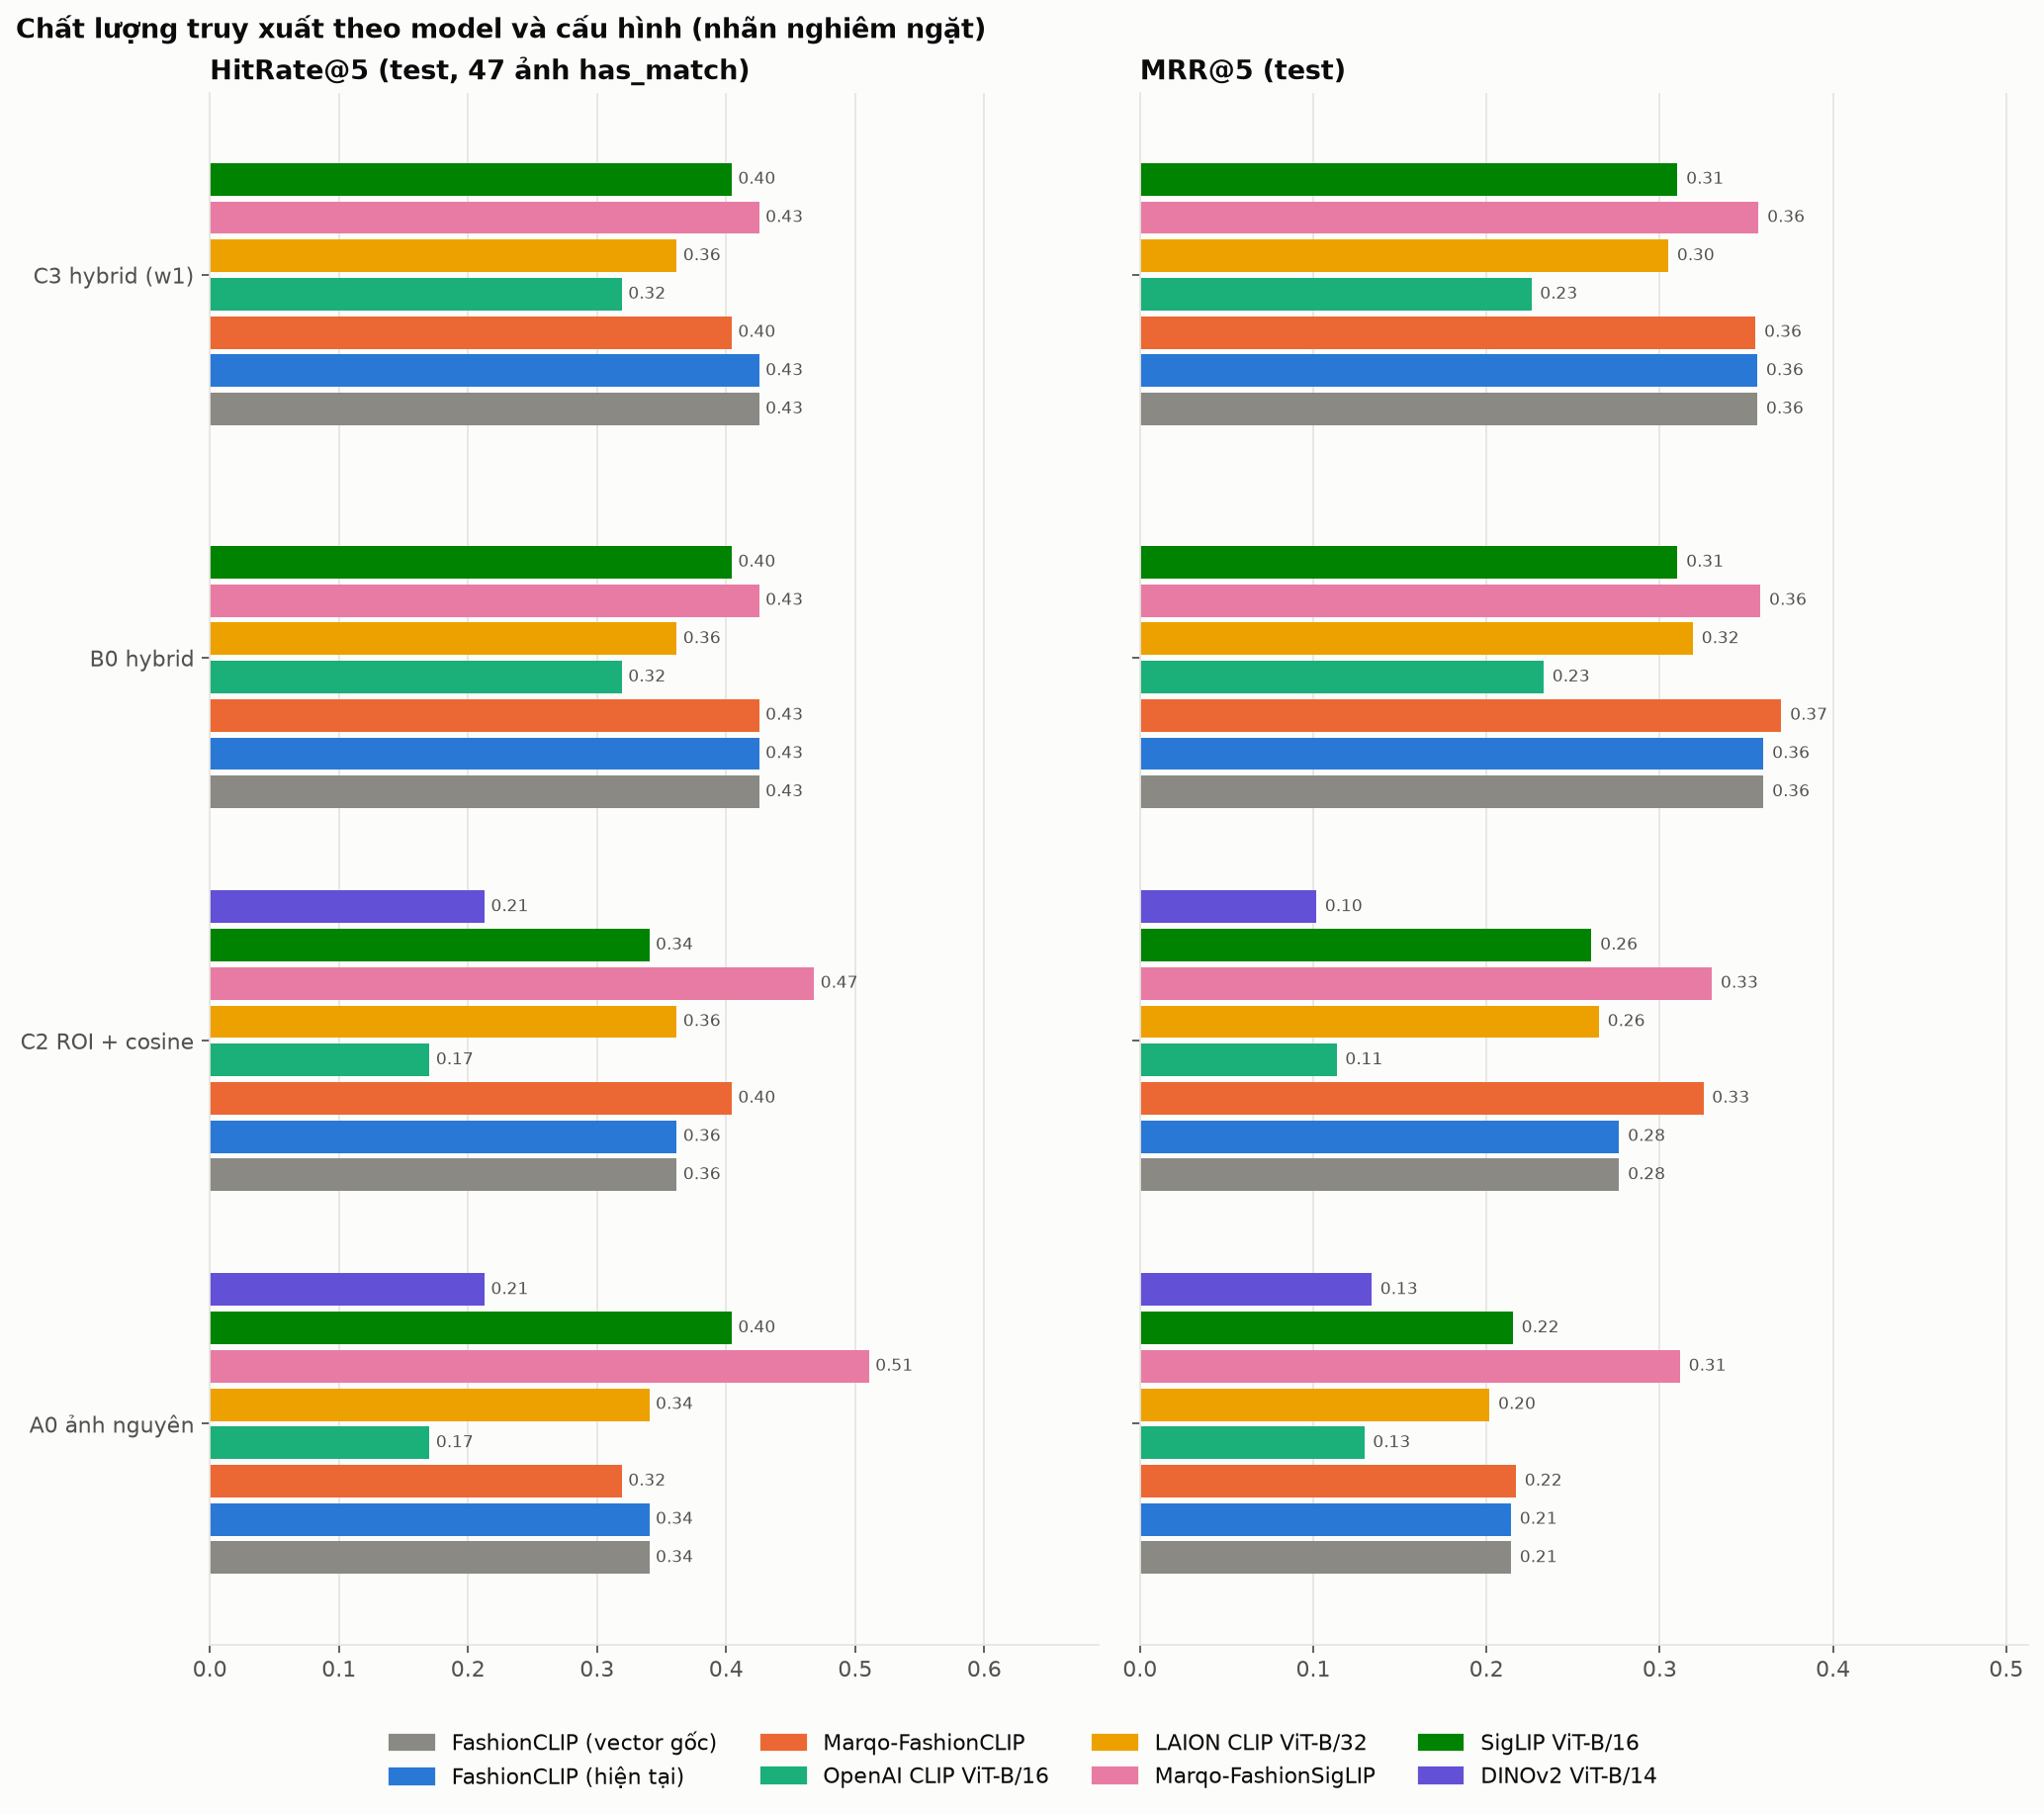

**01_hitrate_mrr_validation.png**

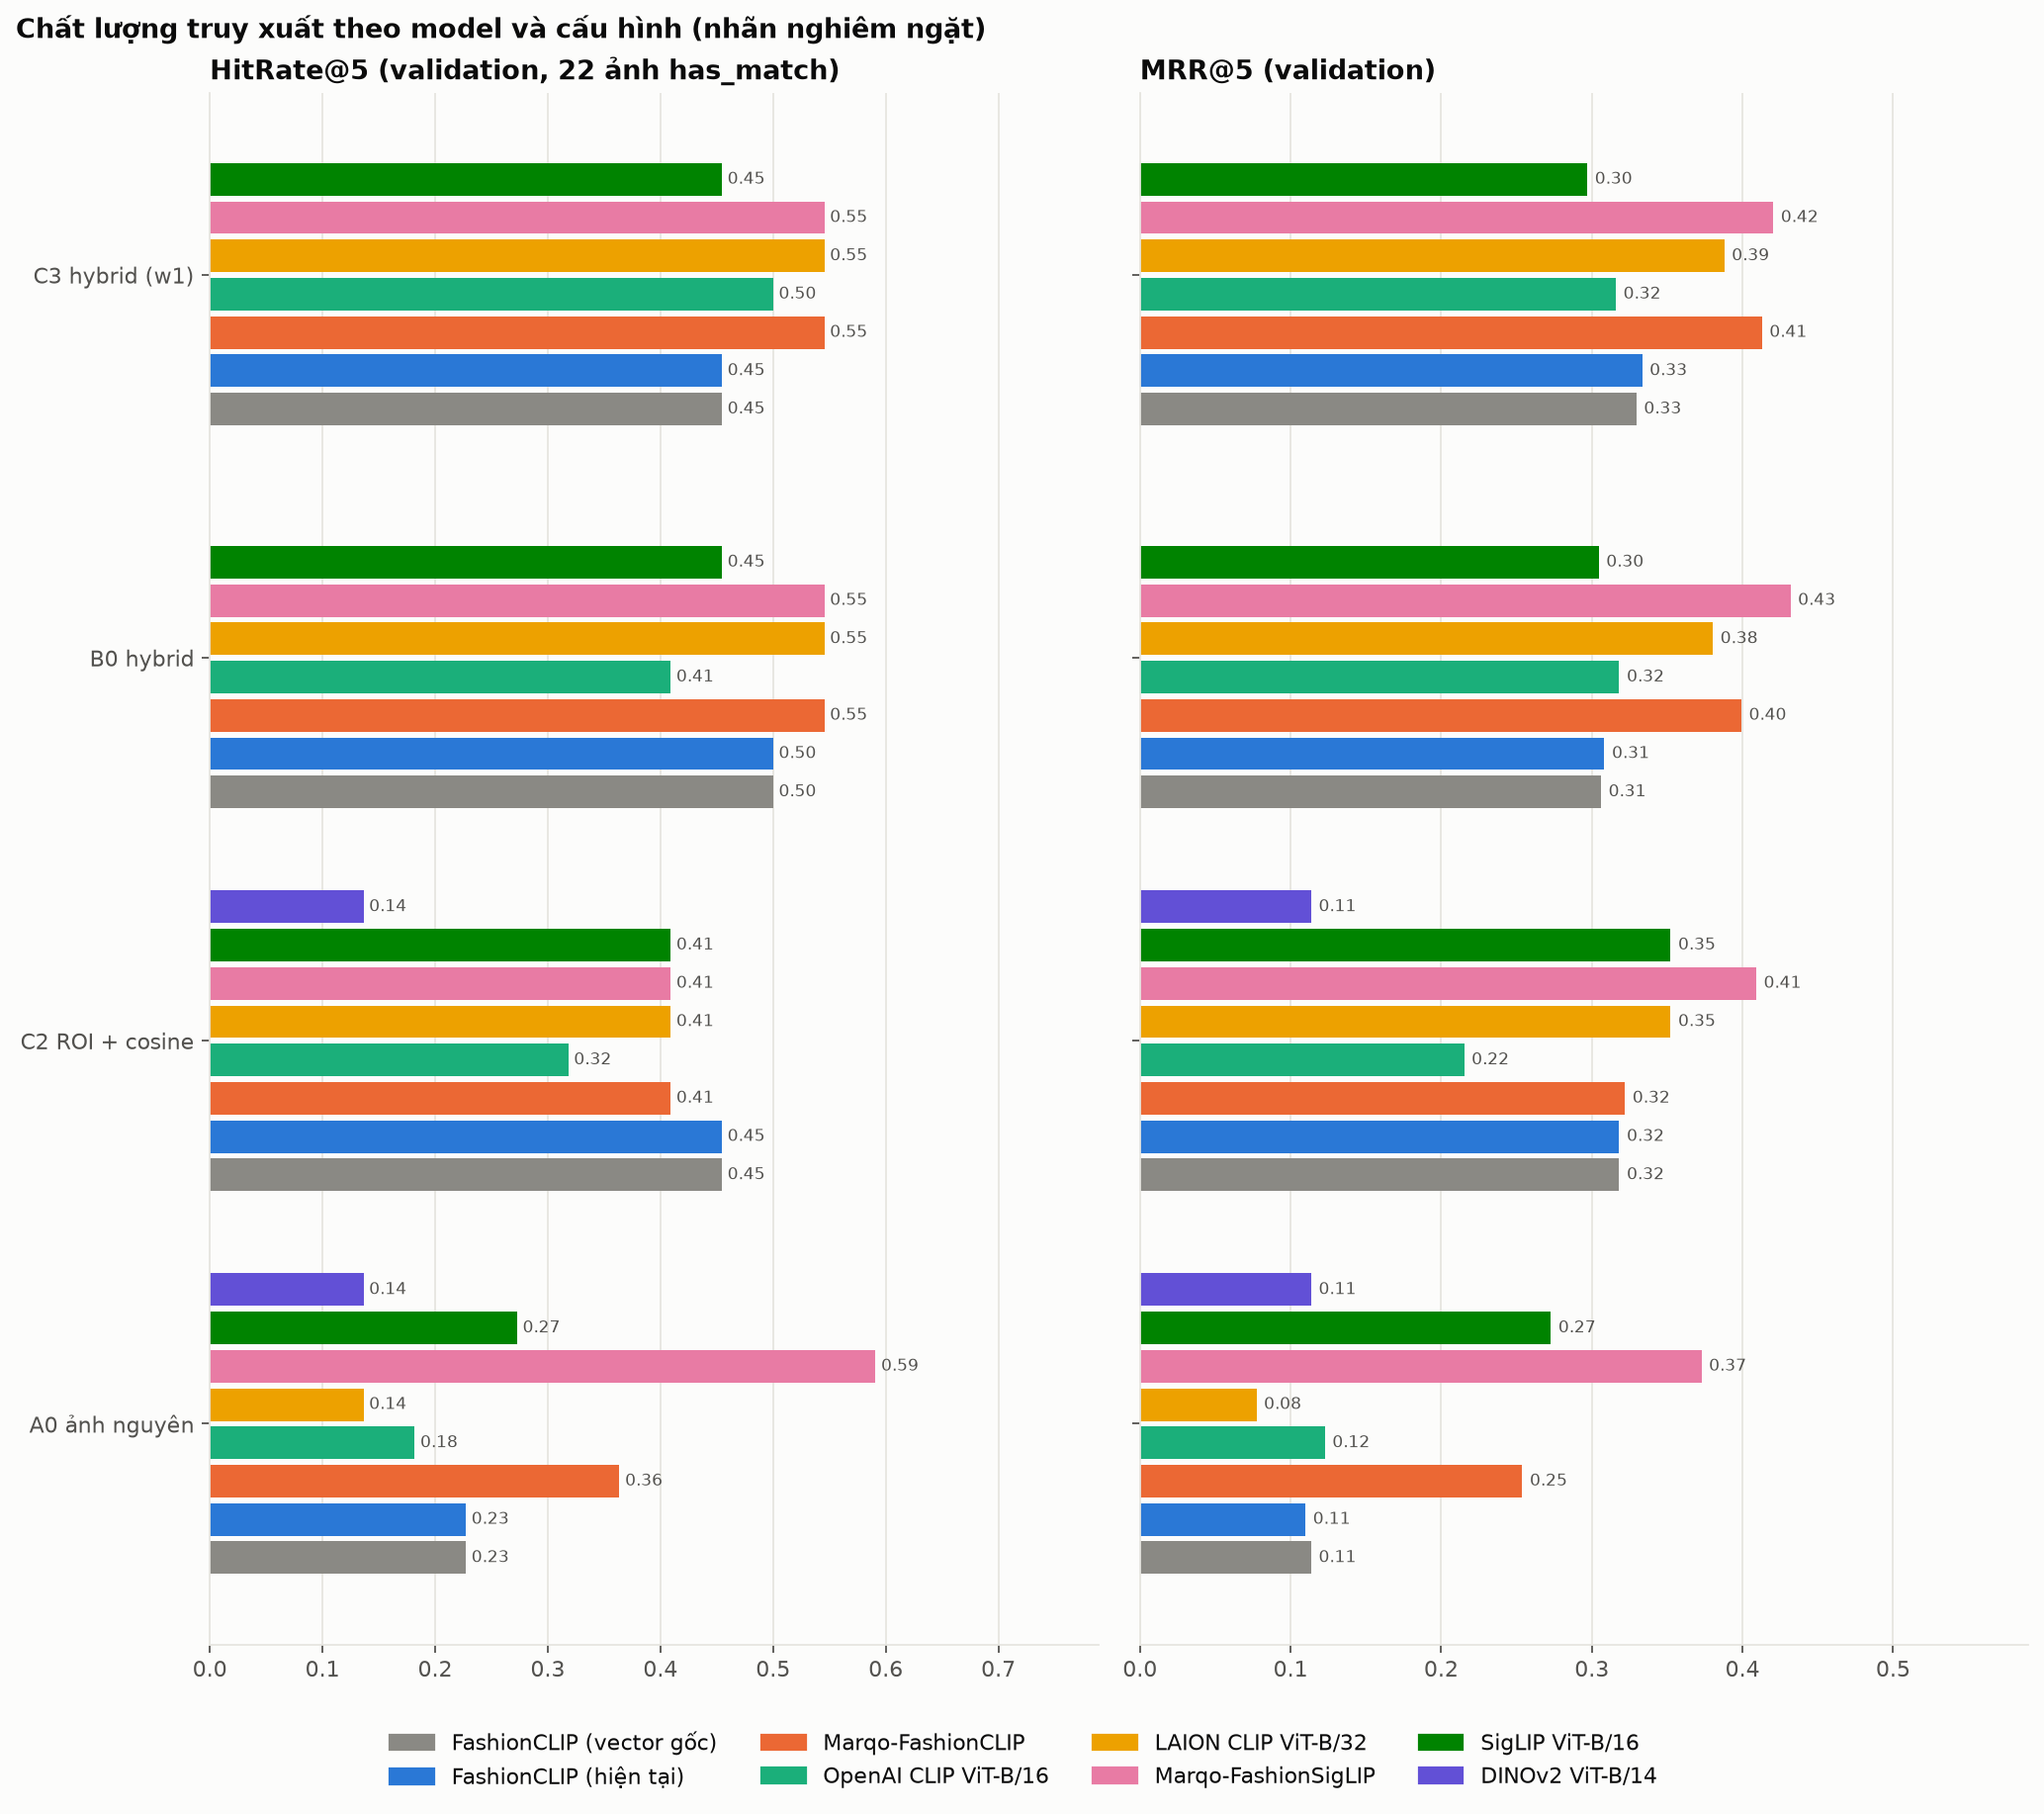

**02_strict_vs_judged_test.png**

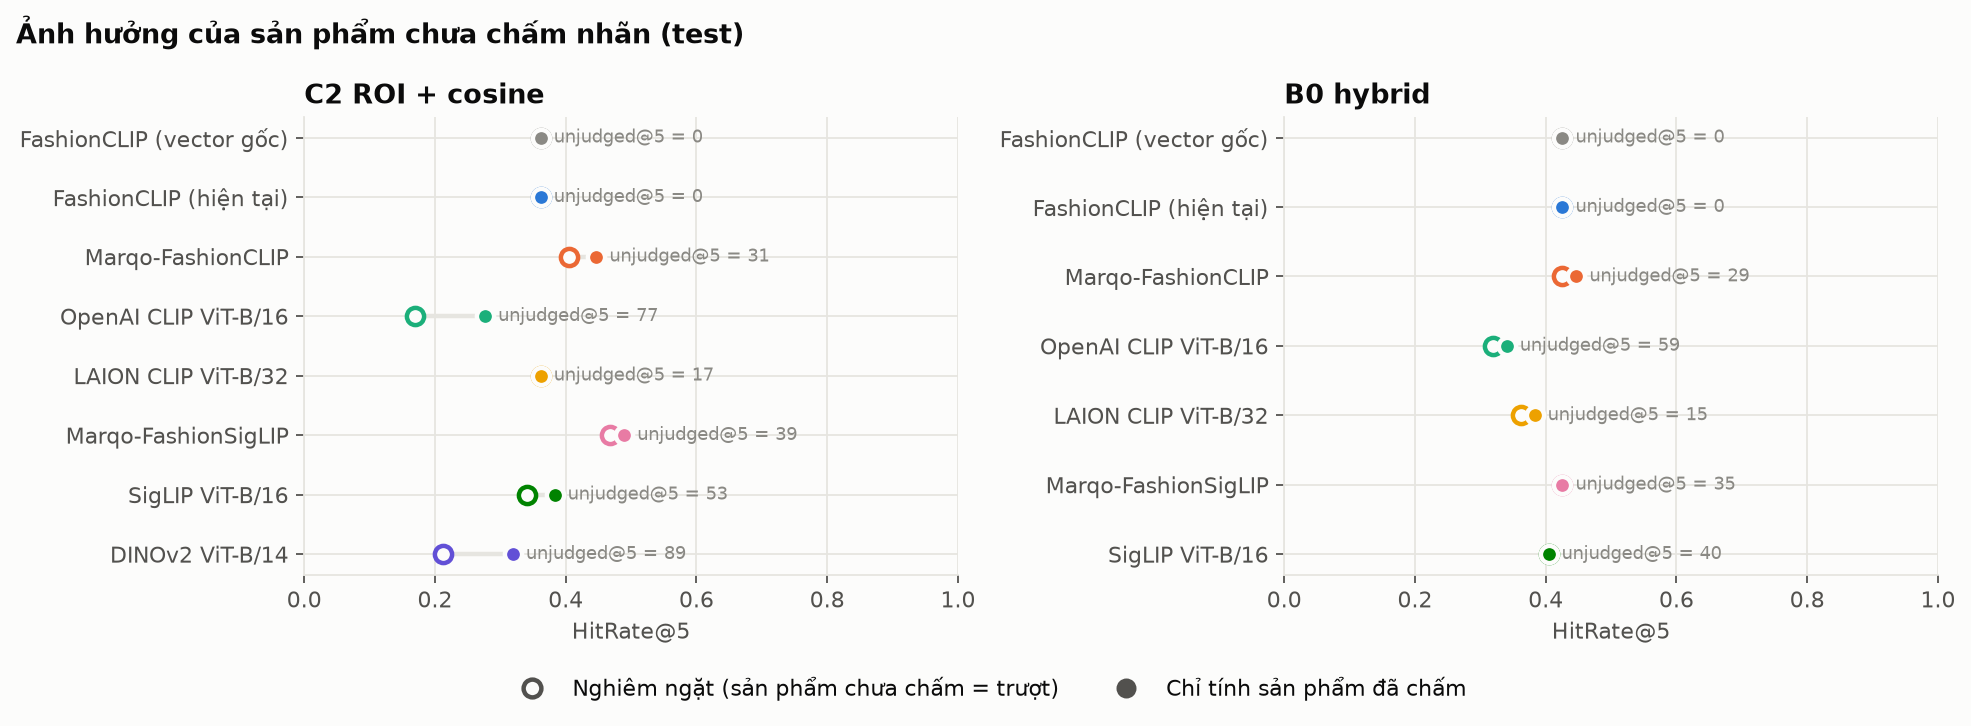

**03_validation_vs_test_C2_embedding_only.png**

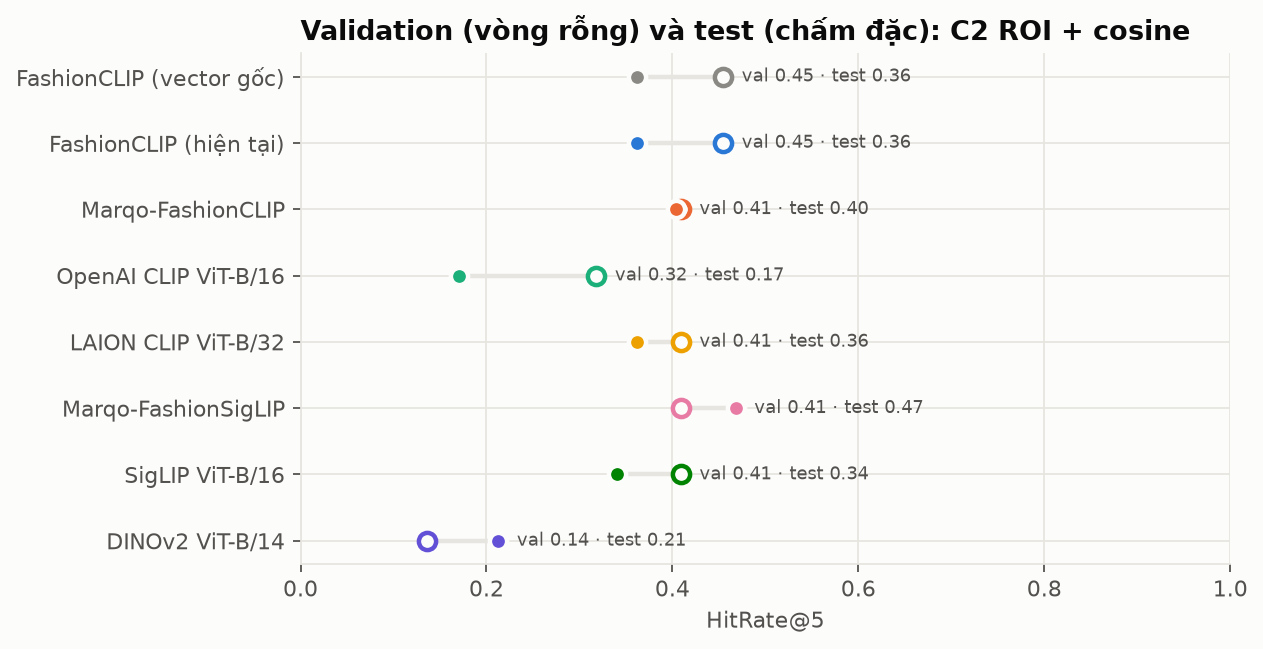

**03_validation_vs_test_B0_current.png**

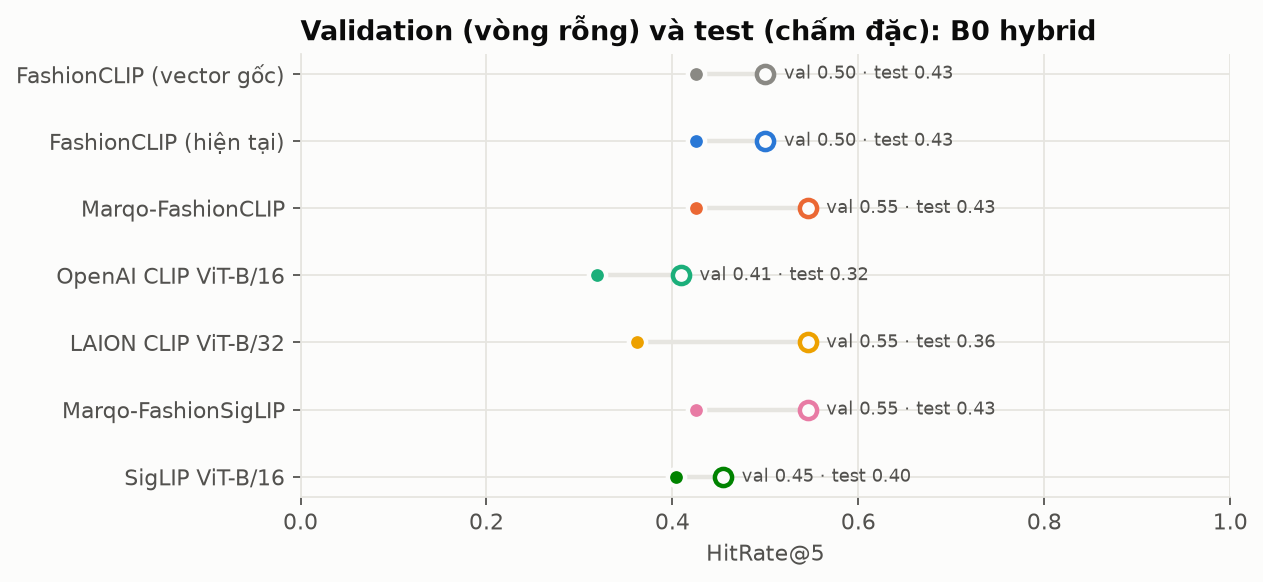

**04_paired_vs_fashionclip_test.png**

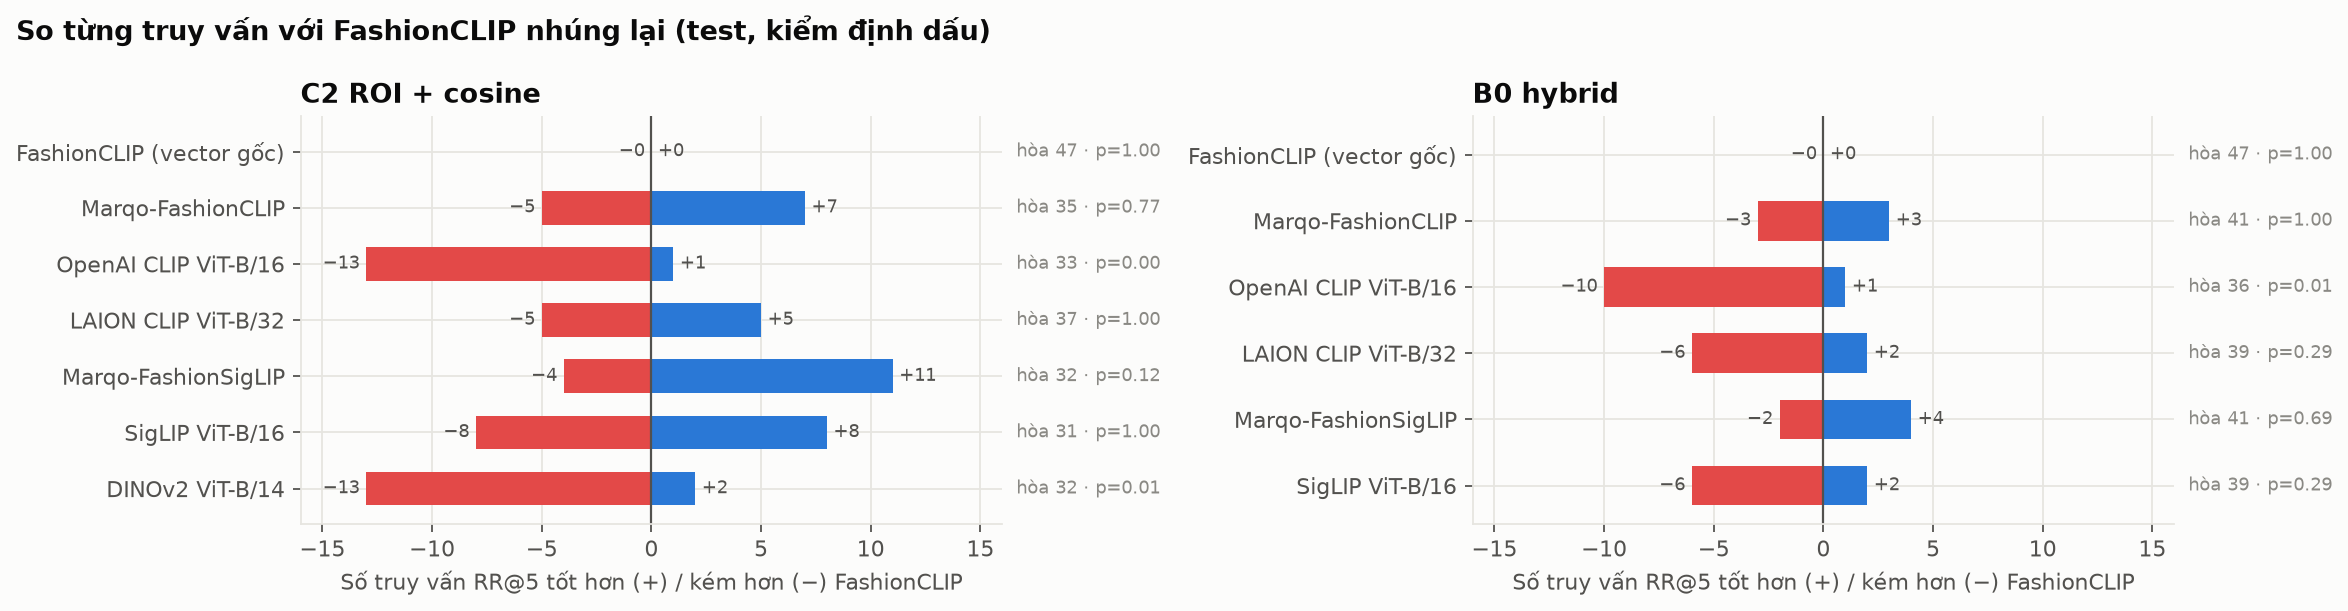

**05_class_heatmap_test_C2_embedding_only.png**

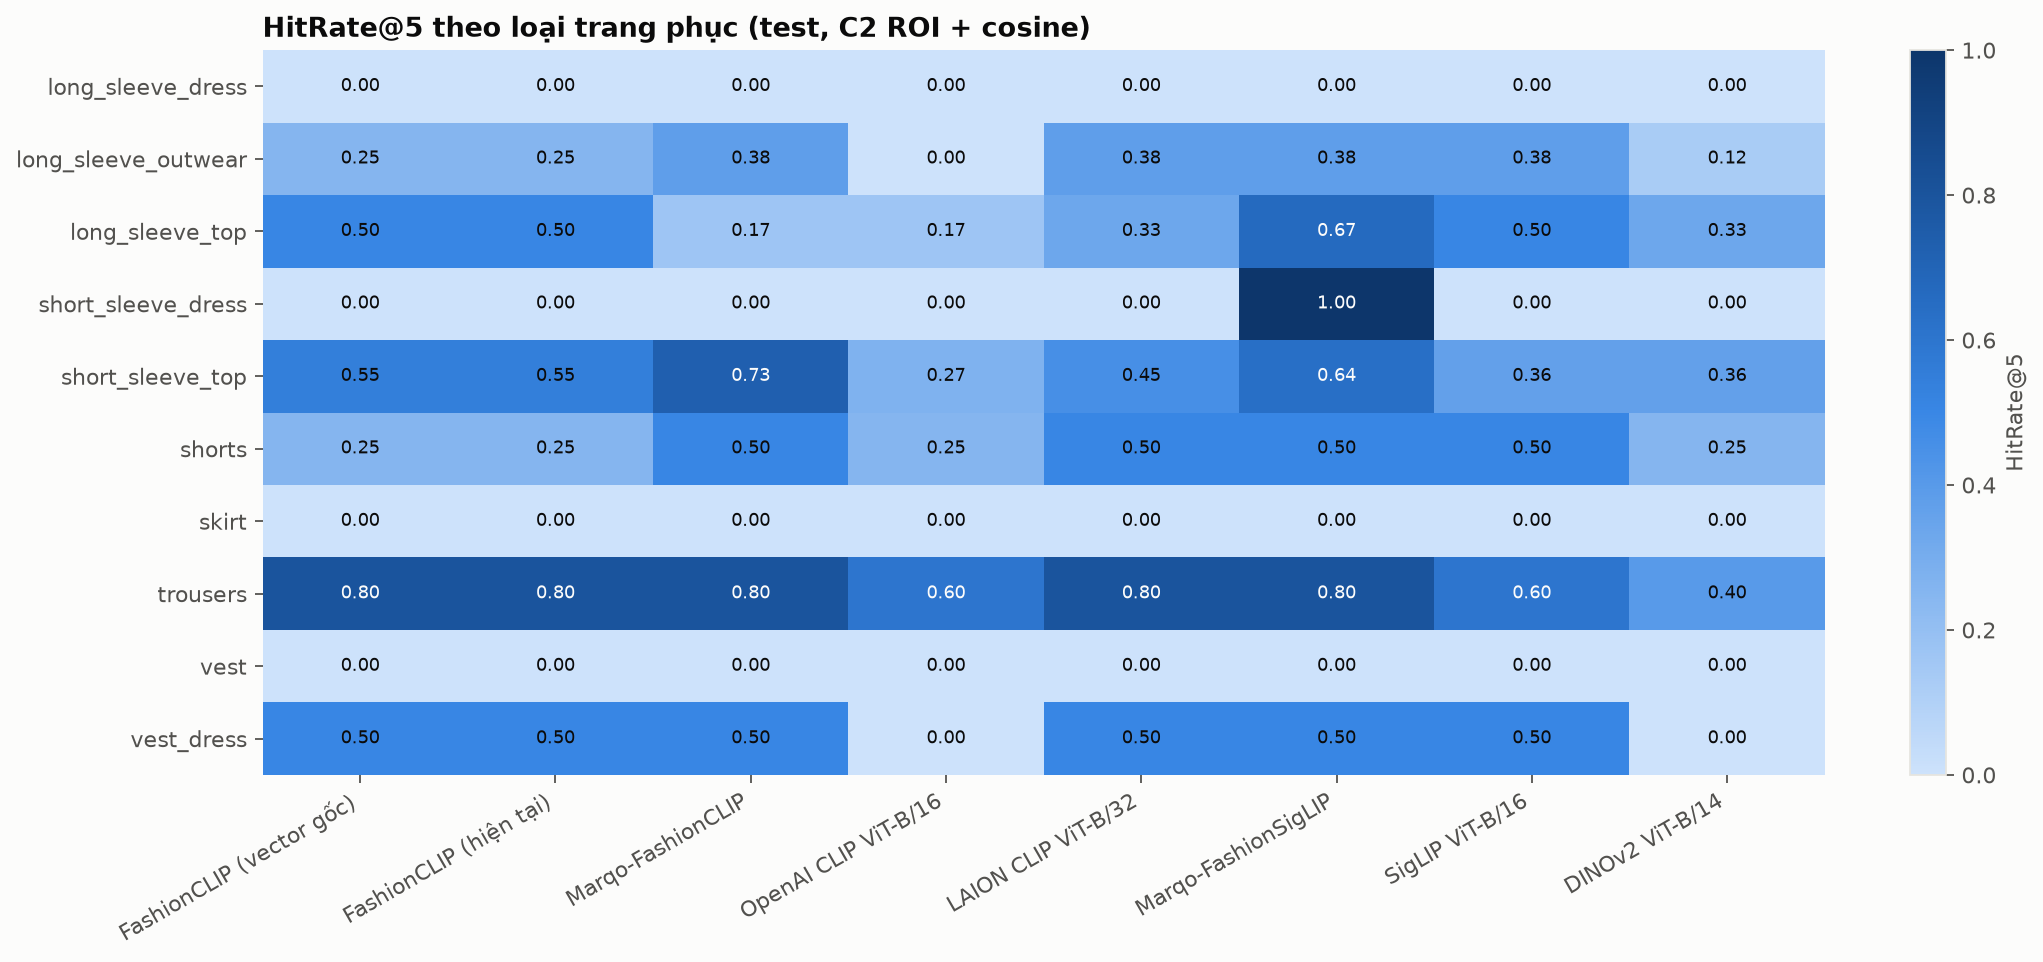

**05_class_heatmap_test_B0_current.png**

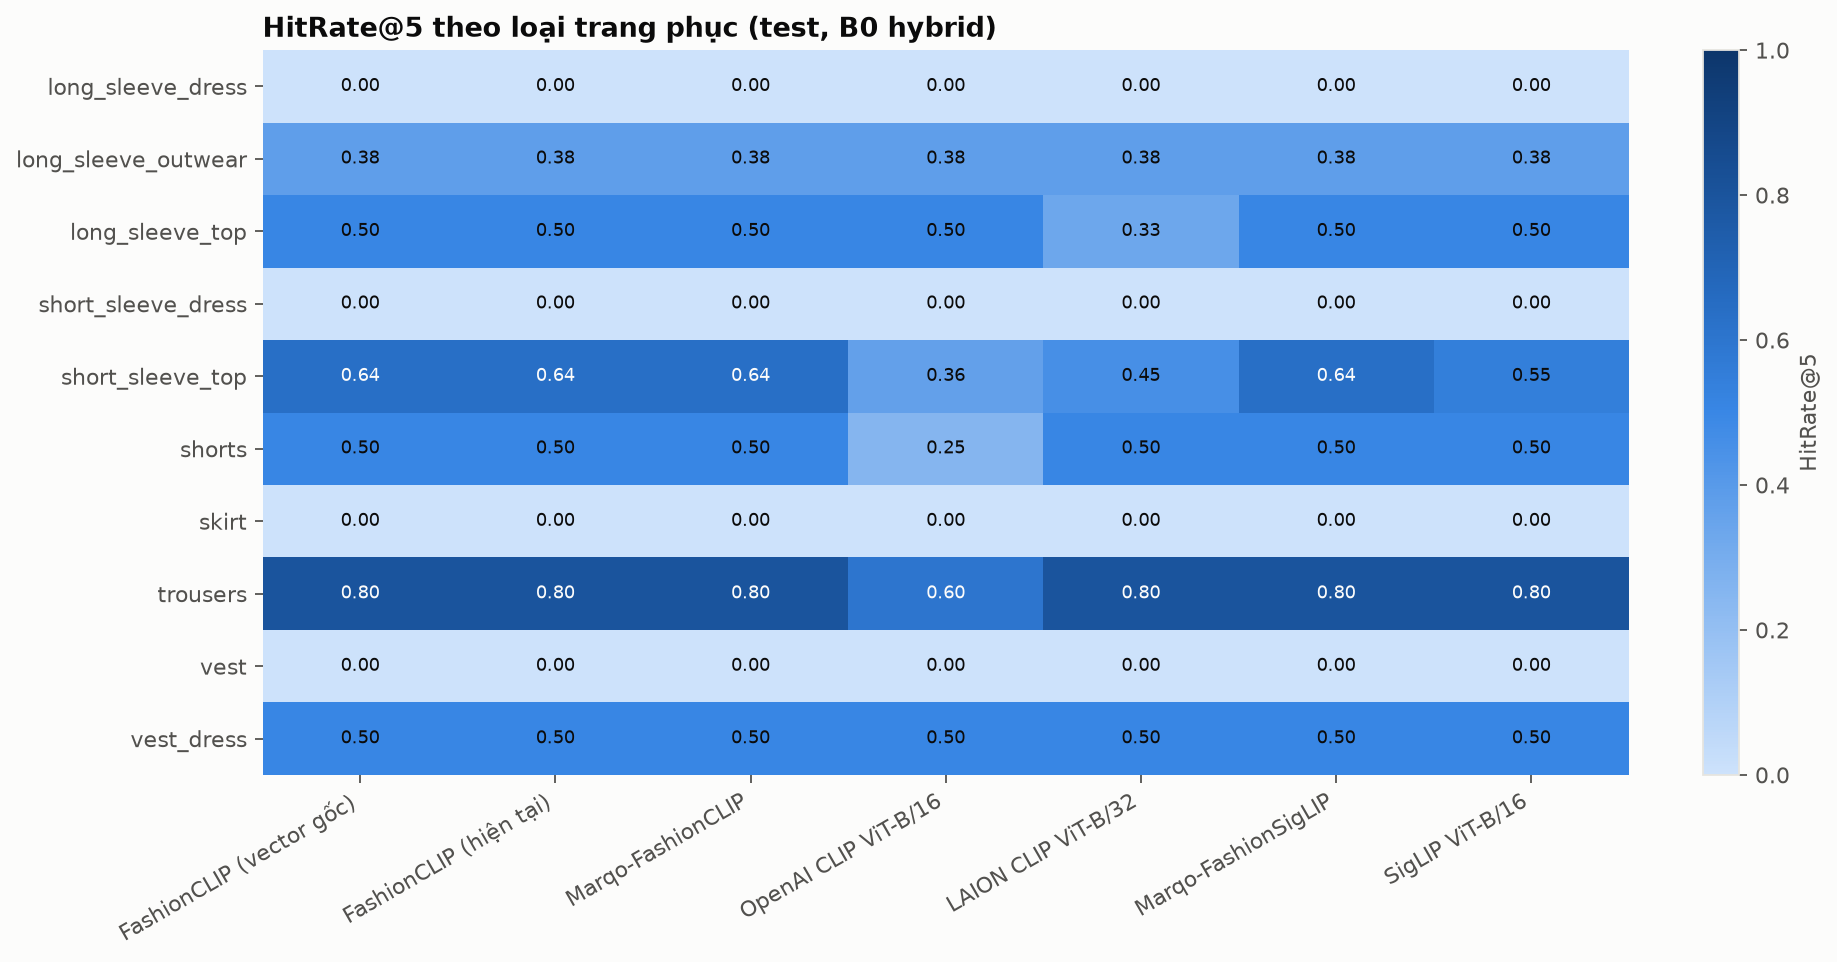

**06_latency_test.png**

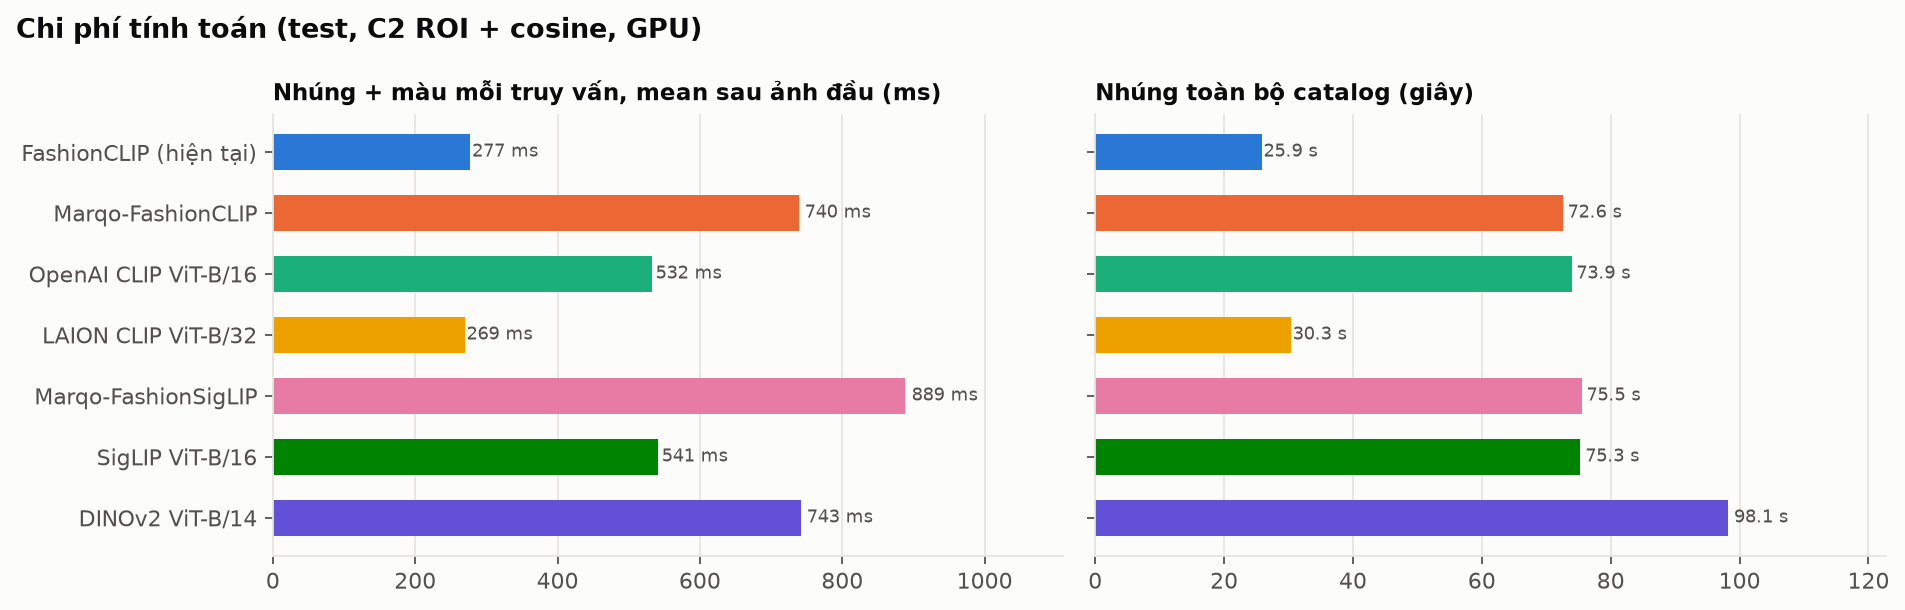

**07_failures_test_C2_embedding_only.png**

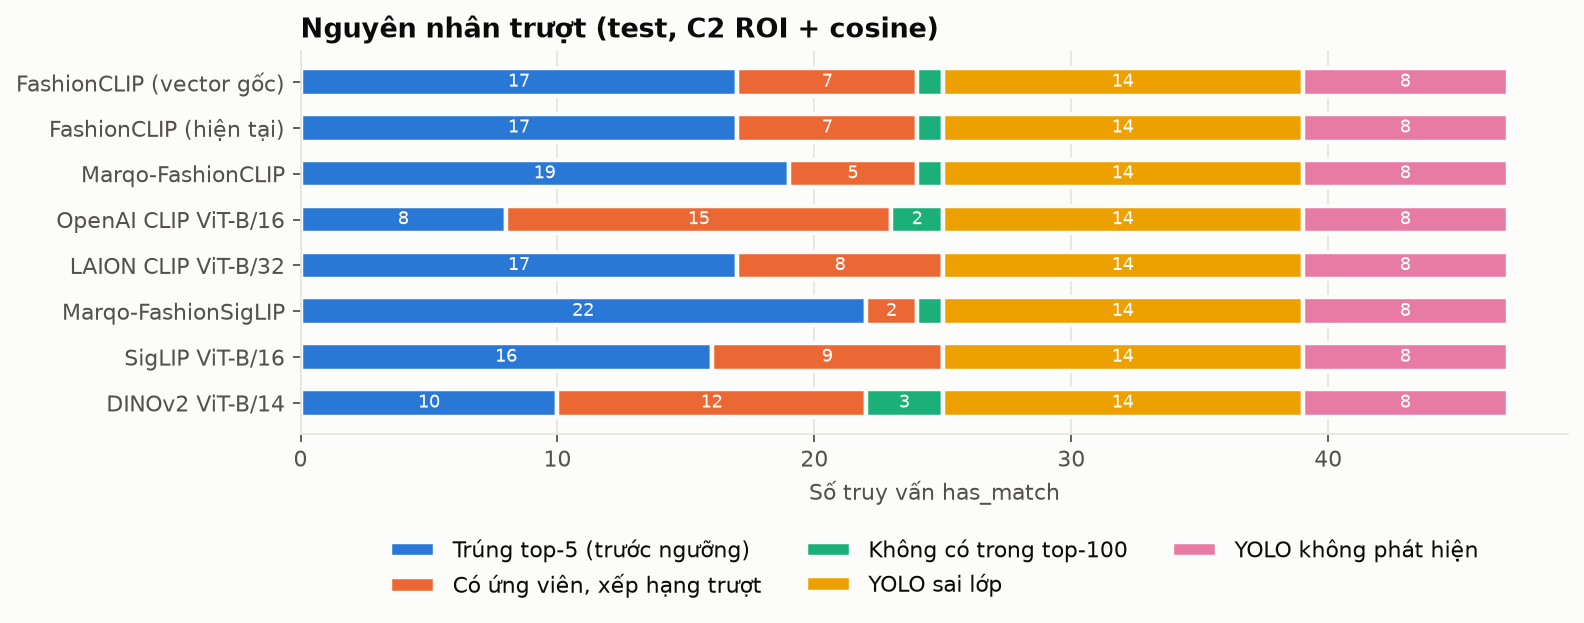

**07_failures_test_B0_current.png**

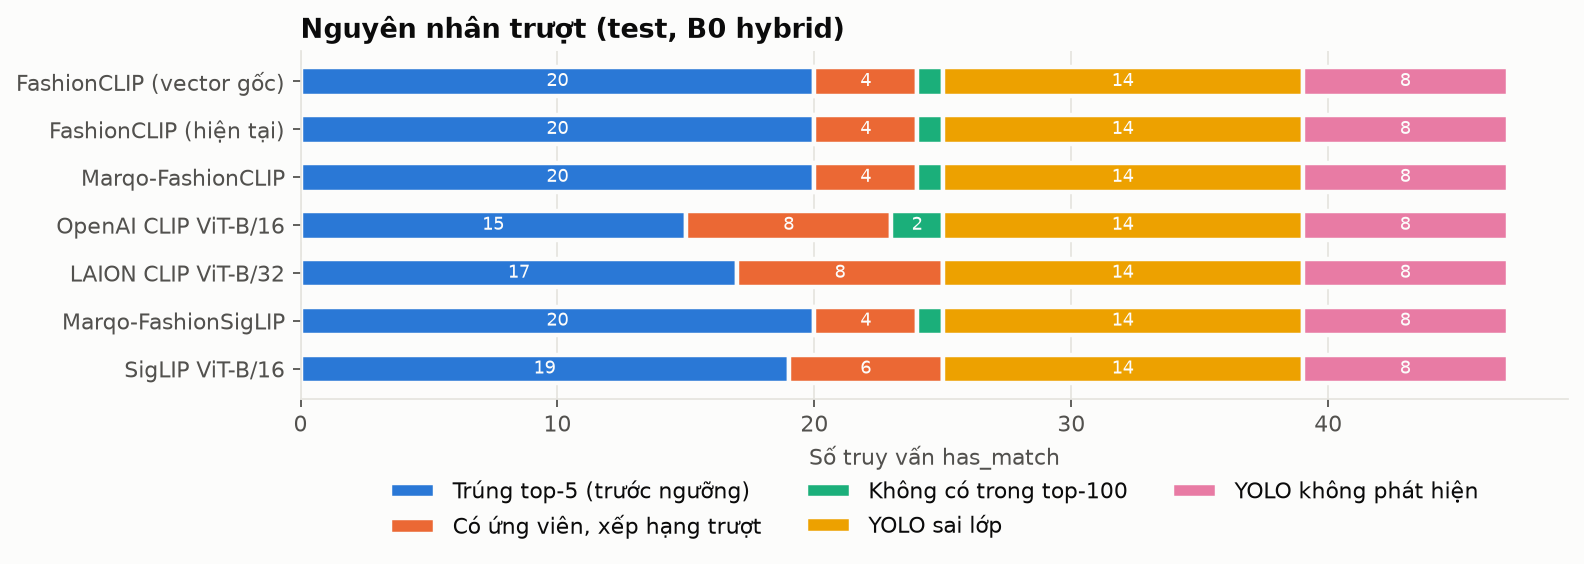

In [7]:
figures = [
    plots.hit_mrr(summary, "test", REPORTS),
    plots.hit_mrr(summary, "validation", REPORTS),
    plots.strict_vs_judged(summary, "test", REPORTS),
    plots.validation_vs_test(summary, REPORTS, "C2_embedding_only"),
    plots.validation_vs_test(summary, REPORTS, "B0_current"),
    plots.paired(paired, "test", REPORTS),
    plots.class_heatmap(class_breakdown(per_query, "test", "C2_embedding_only"), "test", "C2_embedding_only", REPORTS),
    plots.class_heatmap(class_breakdown(per_query, "test", "B0_current"), "test", "B0_current", REPORTS),
    plots.latency(summary, "test", REPORTS),
    plots.failures(failure_counts, "test", "C2_embedding_only", REPORTS),
    plots.failures(failure_counts, "test", "B0_current", REPORTS),
]
import matplotlib.pyplot as plt
plt.close("all")
for path in filter(None, figures):
    display(Markdown(f"**{path.name}**"), Image(filename=str(path)))

## 6. So từng truy vấn với FashionCLIP

In [8]:
display(paired[paired["split"] == "test"].sort_values(["config", "model"]))

,split,config,model,win,loss,tie,sign_test_p
0,test,A0_whole_image,clip_b16,7,11,29,0.481
1,test,A0_whole_image,dinov2_base,5,13,29,0.096
2,test,A0_whole_image,fashionclip_stored,0,0,47,1.000
3,test,A0_whole_image,laion_b32,5,8,34,0.581
4,test,A0_whole_image,marqo_fashionclip,6,8,33,0.791
5,test,A0_whole_image,marqo_fashionsiglip,13,7,27,0.263
6,test,A0_whole_image,siglip_b16,11,11,25,1.000
7,test,B0_current,clip_b16,1,10,36,0.012
8,test,B0_current,fashionclip_stored,0,0,47,1.000
9,test,B0_current,laion_b32,2,6,39,0.289


## 7. Tóm tắt tự động

In [9]:
def best(split, config, metric):
    rows = summary[(summary["split"] == split) & (summary["config"] == config) & (summary["model"] != STORED)]
    top = rows.sort_values(metric, ascending=False).iloc[0]
    return top

lines = ["# Kết quả benchmark model embedding", "",
         "Tạo bởi `evaluation_new/benchmark_models.ipynb`. Test 52 ảnh (47 `has_match`), validation 23 ảnh.", ""]
for config in ("C2_embedding_only", "B0_current"):
    for metric in ("hit_at_5", "mrr_at_5", "judged_hit_at_5"):
        top = best("test", config, metric)
        base = summary[(summary["split"] == "test") & (summary["config"] == config) & (summary["model"] == "fashionclip")]
        ref = float(base[metric].iloc[0]) if not base.empty else float("nan")
        lines.append(f"- {config} · {metric}: cao nhất **{top['label']}** {top[metric]:.3f} (FashionCLIP {ref:.3f})")
lines += ["", "## Bảng test", "", plots.to_markdown(test_table), "",
          "## So từng truy vấn với FashionCLIP (test)", "",
          plots.to_markdown(paired[paired["split"] == "test"]), "",
          "## Biểu đồ", ""] + [f"![{p.stem}]({p.name})" for p in filter(None, figures)]
lines += ["", "## Lưu ý", "",
          "- Nhãn chỉ phủ sản phẩm từng được chấm (chủ yếu từ FashionCLIP). Sản phẩm chưa chấm tính là trượt, nên số nghiêm ngặt thiên vị FashionCLIP; xem `unjudged_at_5` và `judged_*`.",
          "- 47 truy vấn has_match: chênh 1 truy vấn = 0,021 HitRate. Dùng p của kiểm định dấu trước khi kết luận.",
          "- Ngưỡng chấp nhận (0,70 / 0,60) được chỉnh cho FashionCLIP, nên chỉ số sau ngưỡng không so sánh được giữa các model; bảng chỉ dùng chỉ số trước ngưỡng.",
          "- Phát hiện (YOLO) giống hệt nhau ở mọi model nên `target_recall` không đổi."]
(REPORTS / "README.md").write_text("\n".join(lines), encoding="utf-8")
display(Markdown("\n".join(lines[:12])))

# Kết quả benchmark model embedding

Tạo bởi `evaluation_new/benchmark_models.ipynb`. Test 52 ảnh (47 `has_match`), validation 23 ảnh.

- C2_embedding_only · hit_at_5: cao nhất **Marqo-FashionSigLIP** 0.468 (FashionCLIP 0.362)
- C2_embedding_only · mrr_at_5: cao nhất **Marqo-FashionSigLIP** 0.330 (FashionCLIP 0.277)
- C2_embedding_only · judged_hit_at_5: cao nhất **Marqo-FashionSigLIP** 0.489 (FashionCLIP 0.362)
- B0_current · hit_at_5: cao nhất **FashionCLIP (hiện tại)** 0.426 (FashionCLIP 0.426)
- B0_current · mrr_at_5: cao nhất **Marqo-FashionCLIP** 0.370 (FashionCLIP 0.360)
- B0_current · judged_hit_at_5: cao nhất **Marqo-FashionCLIP** 0.447 (FashionCLIP 0.426)

## Bảng test